In [1]:
import matplotlib.pyplot as plt
import pandas as pd


In [2]:
#import data, drop duplicates and throw out unneccesary data points
data = pd.read_csv("data/diabetes_prediction_dataset.csv").drop_duplicates()
data = data[data['gender'] != 'other']
print(data.shape)

(96146, 9)


In [24]:
#histograms
for i in ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']:
    plt.figure()
    plt.hist(data[i], bins = 30)
    plt.title(f'{i} Histogram')
    plt.xlabel(i)
    plt.savefig(f'figures/{i}histogram.png')
    plt.close()

In [25]:
#countplots
for i in ['gender', 'hypertension', 'heart_disease', 'diabetes', 'smoking_history']:
    plt.figure()
    count = data[i].value_counts()
    plt.bar(count.index, count.values)
    plt.title(f'{i} countplot')
    plt.xticks([0, 1])
    plt.xlabel(i)
    plt.savefig(f'figures/{i}-count.png')
    plt.close()

In [26]:
#One hot encoding for gender and smoking history
data['smoking_history'] = data['smoking_history'].replace(['never', 'No Info'], 'never')
data['smoking_history'] = data['smoking_history'].replace(['ever', 'former', 'not current'], 'past')
data = pd.get_dummies(data, columns=['gender'], dtype=int)
data = pd.get_dummies(data, columns=['smoking_history'], dtype=int)

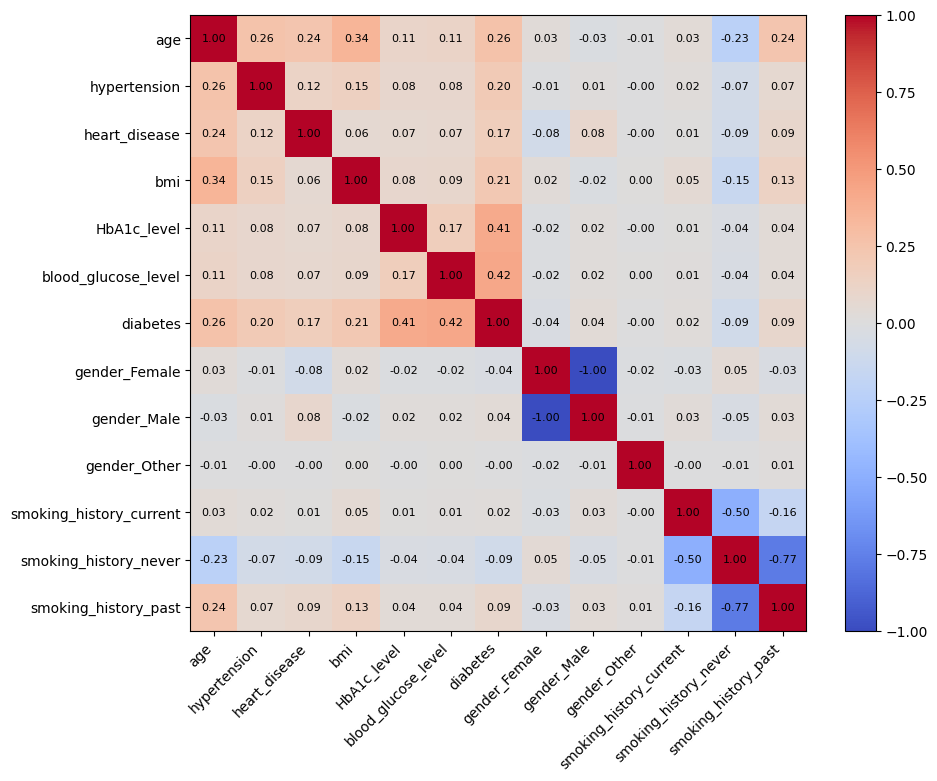

In [27]:
#Correlation Matrix
corr = data.corr()
plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha='right')
plt.yticks(range(len(corr.columns)), corr.columns)
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", 
                 ha="center", va="center", 
                 color="black", fontsize=8)
plt.savefig('figures/corr-matrix.png')

In [31]:
#Data Standardization
data_inputs = data[['age', 'bmi', 'HbA1c_level','blood_glucose_level']]
data[['age', 'bmi', 'HbA1c_level','blood_glucose_level']] = (data_inputs - data_inputs.mean())/data_inputs.std()
print(data.head())

data.to_csv('data/diabetes_prediction_standardized.csv', index=False)

        age  hypertension  heart_disease       bmi  HbA1c_level  \
0  1.700831             0              1 -0.314945     0.994558   
1  0.543369             0              0 -0.000216     0.994558   
2 -0.614092             0              0 -0.000216     0.155969   
3 -0.257950             0              0 -0.572048    -0.496266   
4  1.522760             1              1 -1.061135    -0.682619   

   blood_glucose_level  diabetes  gender_Female  gender_Male  gender_Other  \
0             0.043554         0              1            0             0   
1            -1.423089         0              1            0             0   
2             0.483546         0              0            1             0   
3             0.410214         0              1            0             0   
4             0.410214         0              0            1             0   

   smoking_history_current  smoking_history_never  smoking_history_past  
0                        0                      1     

In [ ]:
from imblearn.over_sampling import SMOTE

# Separate features and target
X = data.drop('diabetes', axis=1)
y = data['diabetes']

# Apply SMOTE
smote = SMOTE(random_state=42)
X_smote, y_smote = smote.fit_resample(X, y)

# Create new balanced dataset
data_balanced = pd.DataFrame(X_smote, columns=X.columns)
data_balanced['diabetes'] = y_smote


data.to_csv('data/diabetes_prediction_standardized_SMOTE.csv', index=False)

: 